# Predictive Modeling for Customer Booking – British Airways

Built as part of the British Airways **Data Science job simulation** (Forage).
The goal: identify which factors most influence whether a customer completes
a flight booking, and train a classifier that predicts booking completion.

**Tools:** Pandas, Scikit-learn, LightGBM, imbalanced-learn (SMOTE), Matplotlib, Seaborn

**Pipeline:** load & explore data &rarr; engineer features &rarr; balance classes
with SMOTE &rarr; train a LightGBM classifier &rarr; evaluate &rarr; interpret
feature importance.

> **About the data:** this notebook ships with `data/sample_customer_booking.csv`,
> a synthetically generated dataset built to match the real Forage file's columns
> and ~85/15 class imbalance, so the notebook runs end-to-end with no extra setup.
> Drop your real `customer_booking.csv` from Forage into `data/` (identical column
> names) to reproduce your actual simulation results — no code changes needed.
>
> **About dependencies:** if `lightgbm` / `imbalanced-learn` aren't installed, the
> code below automatically falls back to `GradientBoostingClassifier` and a small
> from-scratch SMOTE implementation, so it still runs. Install `requirements.txt`
> to use the real LightGBM + SMOTE referenced above.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve, f1_score
)

try:
    import lightgbm as lgb
    HAVE_LGBM = True
except ImportError:
    from sklearn.ensemble import GradientBoostingClassifier
    HAVE_LGBM = False

try:
    from imblearn.over_sampling import SMOTE
    HAVE_IMBLEARN = True
except ImportError:
    HAVE_IMBLEARN = False

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

print('LightGBM available:', HAVE_LGBM)
print('imbalanced-learn available:', HAVE_IMBLEARN)

LightGBM available: False
imbalanced-learn available: False


## 1. Load the data

In [2]:
df = pd.read_csv('../data/sample_customer_booking.csv', encoding='latin-1')
print(df.shape)
print(df.head().to_string())

(6000, 14)
   num_passengers sales_channel  trip_type  purchase_lead  length_of_stay  flight_hour flight_day   route booking_origin  wants_extra_baggage  wants_preferred_seat  wants_in_flight_meals  flight_duration  booking_complete
0               1      Internet     OneWay            115             202            8        Tue  HGHAKL      Australia                    1                     0                      1             4.18                 0
1               4      Internet  RoundTrip            173              54            8        Sat  HGHAKL          India                    0                     0                      0             7.91                 0
2               4      Internet  RoundTrip            430             142           23        Wed  KIXAKL  United States                    0                     0                      0             6.04                 0
3               3      Internet  RoundTrip             51             319           17        Thu  SI

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         6000 non-null   int64  
 1   sales_channel          6000 non-null   str    
 2   trip_type              6000 non-null   str    
 3   purchase_lead          6000 non-null   int64  
 4   length_of_stay         6000 non-null   int64  
 5   flight_hour            6000 non-null   int64  
 6   flight_day             6000 non-null   str    
 7   route                  6000 non-null   str    
 8   booking_origin         6000 non-null   str    
 9   wants_extra_baggage    6000 non-null   int64  
 10  wants_preferred_seat   6000 non-null   int64  
 11  wants_in_flight_meals  6000 non-null   int64  
 12  flight_duration        6000 non-null   float64
 13  booking_complete       6000 non-null   int64  
dtypes: float64(1), int64(8), str(5)
memory usage: 656.4 KB


In [4]:
print(df.describe(include='all').transpose().to_string())

                        count unique          top  freq        mean         std  min    25%    50%     75%    max
num_passengers         6000.0    NaN          NaN   NaN      2.9885     1.41399  1.0    2.0    3.0     4.0    5.0
sales_channel            6000      2     Internet  5310         NaN         NaN  NaN    NaN    NaN     NaN    NaN
trip_type                6000      3    RoundTrip  4949         NaN         NaN  NaN    NaN    NaN     NaN    NaN
purchase_lead          6000.0    NaN          NaN   NaN  250.683167   145.46606  0.0  123.0  253.0  375.25  499.0
length_of_stay         6000.0    NaN          NaN   NaN      200.67  116.640103  0.0   99.0  202.0   302.0  399.0
flight_hour            6000.0    NaN          NaN   NaN   11.451167     6.90318  0.0   5.75   11.0    17.0   23.0
flight_day               6000      7          Tue   894         NaN         NaN  NaN    NaN    NaN     NaN    NaN
route                    6000     20       KIXAKL   334         NaN         NaN  NaN    

In [5]:
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else 'No missing values found.')

No missing values found.


## 2. Exploratory Data Analysis

### Target variable: `booking_complete`

booking_complete
0    0.839167
1    0.160833


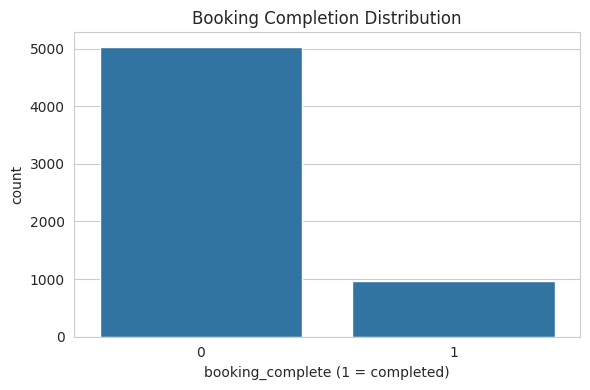

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x='booking_complete', data=df, ax=ax)
ax.set_title('Booking Completion Distribution')
ax.set_xlabel('booking_complete (1 = completed)')
plt.tight_layout()
plt.show()

counts = df['booking_complete'].value_counts(normalize=True).rename('proportion')
print(counts.to_string())

### Categorical features

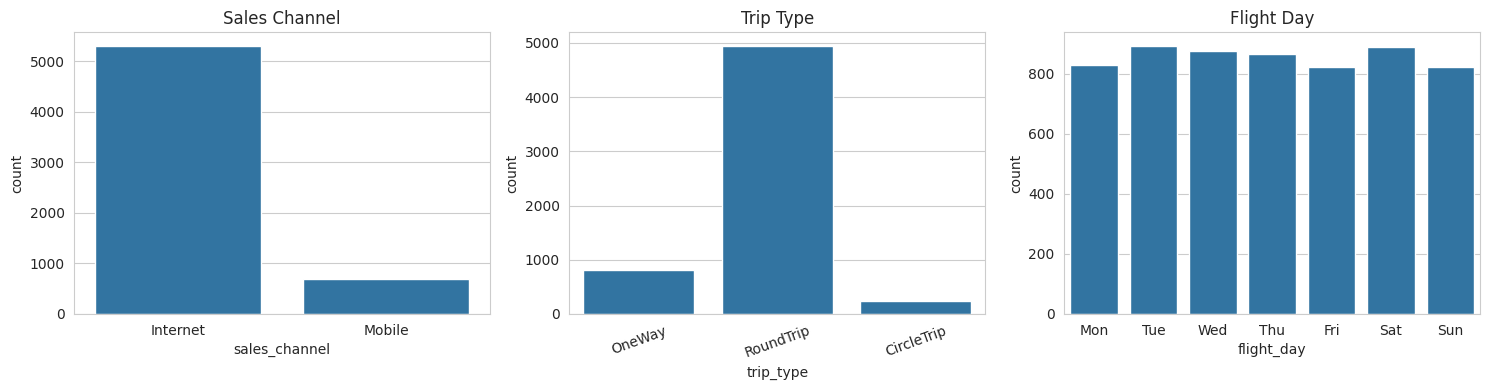

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x='sales_channel', data=df, ax=axes[0])
axes[0].set_title('Sales Channel')
sns.countplot(x='trip_type', data=df, ax=axes[1])
axes[1].set_title('Trip Type')
axes[1].tick_params(axis='x', rotation=20)
sns.countplot(x='flight_day', data=df, ax=axes[2],
              order=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
axes[2].set_title('Flight Day')
plt.tight_layout()
plt.show()

booking_origin
New Zealand    1357
Australia      1027
India           597
China           492
Malaysia        483
Japan           370
South Korea     362
Indonesia       292
Singapore       281
Thailand        195


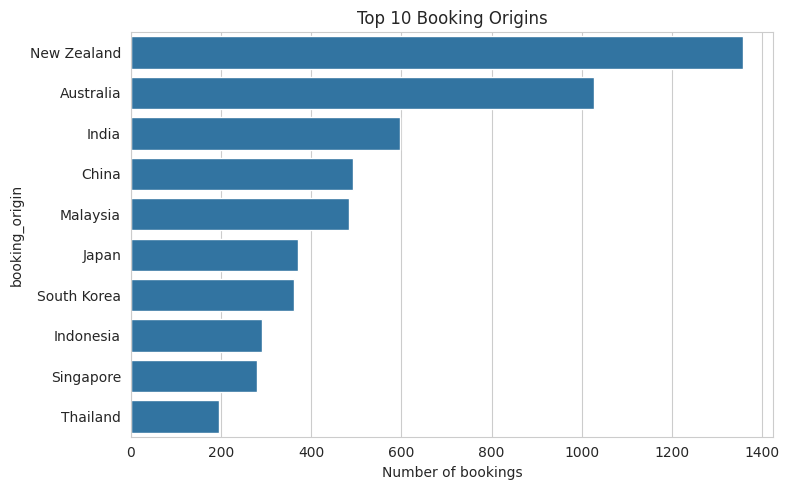

In [8]:
top_origins = df['booking_origin'].value_counts().head(10)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=top_origins.values, y=top_origins.index, ax=ax)
ax.set_title('Top 10 Booking Origins')
ax.set_xlabel('Number of bookings')
plt.tight_layout()
plt.show()
print(top_origins.to_string())

### Numeric feature distributions

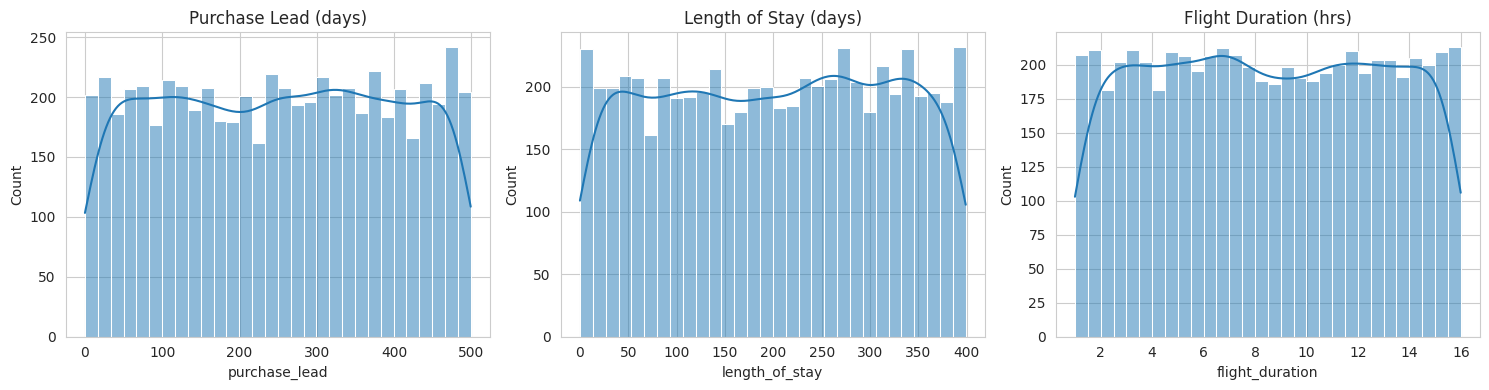

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['purchase_lead'], bins=30, ax=axes[0], kde=True)
axes[0].set_title('Purchase Lead (days)')
sns.histplot(df['length_of_stay'], bins=30, ax=axes[1], kde=True)
axes[1].set_title('Length of Stay (days)')
sns.histplot(df['flight_duration'], bins=30, ax=axes[2], kde=True)
axes[2].set_title('Flight Duration (hrs)')
plt.tight_layout()
plt.show()

### Correlations

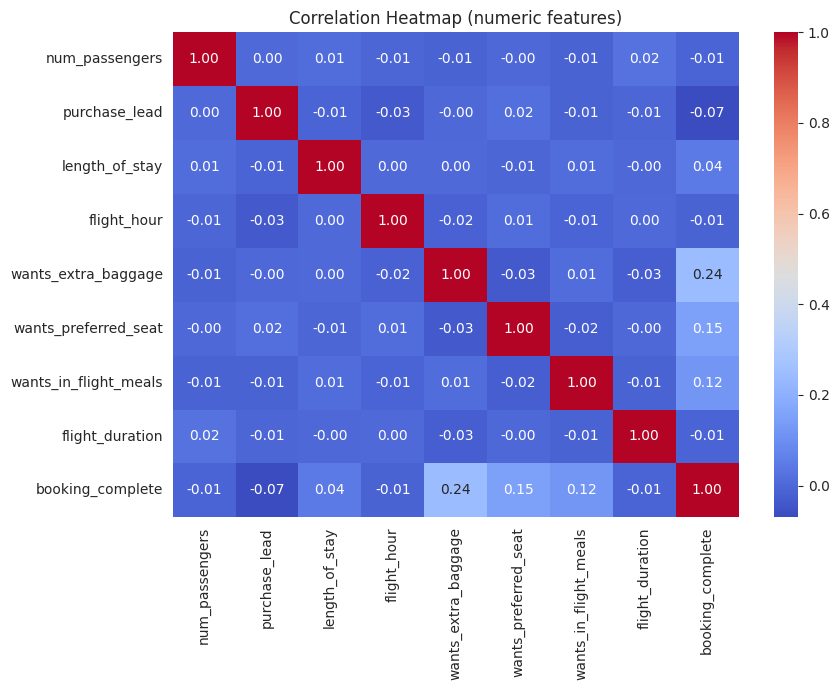

In [10]:
numeric_cols = ['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour',
                 'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals',
                 'flight_duration', 'booking_complete']
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Correlation Heatmap (numeric features)')
plt.tight_layout()
plt.show()

## 3. Feature engineering & preprocessing

`route` and `booking_origin` are high-cardinality categoricals, so they're
frequency-encoded rather than one-hot encoded (which would blow up the
feature space). The remaining categoricals are one-hot encoded.

In [11]:
df_enc = df.copy()

for col in ['route', 'booking_origin']:
    freq_map = df_enc[col].value_counts(normalize=True)
    df_enc[col + '_freq'] = df_enc[col].map(freq_map)
    df_enc.drop(columns=[col], inplace=True)

df_enc = pd.get_dummies(df_enc, columns=['sales_channel', 'trip_type', 'flight_day'], drop_first=True)

print('Encoded feature matrix shape:', df_enc.shape)
print(df_enc.head().to_string())

Encoded feature matrix shape: (6000, 20)
   num_passengers  purchase_lead  length_of_stay  flight_hour  wants_extra_baggage  wants_preferred_seat  wants_in_flight_meals  flight_duration  booking_complete  route_freq  booking_origin_freq  sales_channel_Mobile  trip_type_OneWay  trip_type_RoundTrip  flight_day_Mon  flight_day_Sat  flight_day_Sun  flight_day_Thu  flight_day_Tue  flight_day_Wed
0               1            115             202            8                    1                     0                      1             4.18                 0    0.048000             0.171167                 False              True                False           False           False           False           False            True           False
1               4            173              54            8                    0                     0                      0             7.91                 0    0.048000             0.099500                 False             False                 T

## 4. Train/test split

In [12]:
X = df_enc.drop(columns=['booking_complete'])
y = df_enc['booking_complete']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train shape:', X_train.shape, ' Test shape:', X_test.shape)
print('Train positive rate:', round(y_train.mean(), 3), ' Test positive rate:', round(y_test.mean(), 3))

Train shape: (4800, 19)  Test shape: (1200, 19)
Train positive rate: 0.161  Test positive rate: 0.161


## 5. Handling class imbalance with SMOTE

`booking_complete` is imbalanced (roughly 85/15), so a model trained on it
as-is tends to just learn to predict "not completed" every time. SMOTE
oversamples the minority class by interpolating between nearest neighbors —
applied to the **training set only**, never the test set, to avoid leakage.

In [13]:
def simple_smote(X, y, minority_class=1, k=5, random_state=42):
    """Lightweight from-scratch SMOTE, used only if imbalanced-learn isn't installed."""
    rng = np.random.default_rng(random_state)
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    X_min = X[y == minority_class]
    n_needed = (y != minority_class).sum() - (y == minority_class).sum()
    if n_needed <= 0 or len(X_min) < 2:
        return X, y
    k = min(k, len(X_min) - 1)
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X_min)
    _, all_idx = nn.kneighbors(X_min)
    synthetic = []
    for _ in range(n_needed):
        i = rng.integers(0, len(X_min))
        neighbor = all_idx[i][rng.integers(1, k + 1)]
        gap = rng.random()
        synthetic.append(X_min[i] + gap * (X_min[neighbor] - X_min[i]))
    X_res = np.vstack([X, np.array(synthetic)])
    y_res = np.concatenate([y, np.full(len(synthetic), minority_class)])
    return X_res, y_res


if HAVE_IMBLEARN:
    smote = SMOTE(random_state=42)
    X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
    balance_method = 'imbalanced-learn SMOTE'
else:
    X_res, y_res = simple_smote(X_train.values, y_train.values, random_state=42)
    X_train_res = pd.DataFrame(X_res, columns=X_train.columns)
    y_train_res = pd.Series(y_res).astype(int)
    balance_method = 'lightweight from-scratch SMOTE fallback (imbalanced-learn not installed)'

print('Balancing method used:', balance_method)
print('Resampled train shape:', X_train_res.shape)
print('Resampled positive rate:', round(y_train_res.mean(), 3))

Balancing method used: lightweight from-scratch SMOTE fallback (imbalanced-learn not installed)
Resampled train shape: (8056, 19)
Resampled positive rate: 0.5


## 6. Train the model

In [14]:
if HAVE_LGBM:
    model = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        random_state=42,
    )
    model_name = 'LightGBM'
else:
    model = GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        random_state=42,
    )
    model_name = 'GradientBoostingClassifier (LightGBM fallback)'

model.fit(X_train_res, y_train_res)
print('Trained model:', model_name)

Trained model: GradientBoostingClassifier (LightGBM fallback)


## 7. Model evaluation

              precision    recall  f1-score   support

           0      0.859     0.952     0.903      1007
           1      0.422     0.181     0.254       193

    accuracy                          0.828      1200
   macro avg      0.640     0.567     0.578      1200
weighted avg      0.788     0.828     0.799      1200



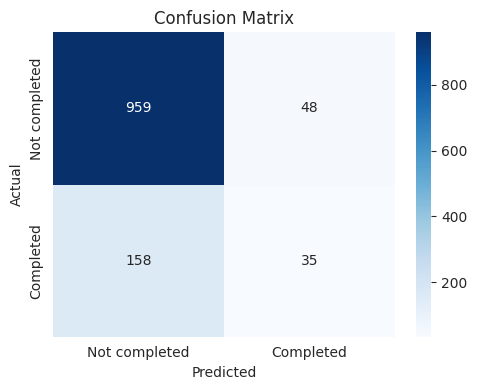

In [15]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, digits=3))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Not completed', 'Completed'],
            yticklabels=['Not completed', 'Completed'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

ROC-AUC: 0.705
F1 score: 0.254


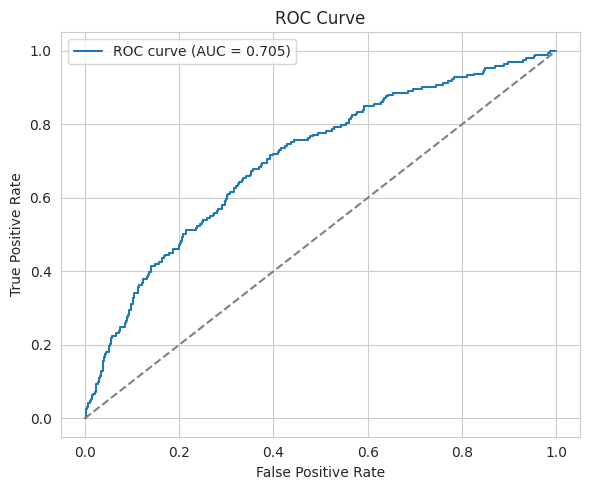

In [16]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f'ROC curve (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend()
plt.tight_layout()
plt.show()

print(f'ROC-AUC: {auc:.3f}')
print(f'F1 score: {f1_score(y_test, y_pred):.3f}')

### Threshold tuning

SMOTE balances the *training* set, but the *test* set (and the real world)
stays imbalanced — so the default 0.5 probability cutoff tends to under-call
the minority class. Picking the threshold that maximizes F1 on the
precision-recall curve gives a fairer read of what the model actually learned.

In [17]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-9)
best_idx = f1_scores[:-1].argmax()
best_threshold = thresholds[best_idx]

y_pred_tuned = (y_proba >= best_threshold).astype(int)

print(f'Best threshold by F1: {best_threshold:.3f}  (vs. default 0.5)')
print(classification_report(y_test, y_pred_tuned, digits=3))

Best threshold by F1: 0.256  (vs. default 0.5)
              precision    recall  f1-score   support

           0      0.894     0.785     0.836      1007
           1      0.313     0.513     0.389       193

    accuracy                          0.741      1200
   macro avg      0.603     0.649     0.612      1200
weighted avg      0.800     0.741     0.764      1200



wants_extra_baggage      0.492000
wants_preferred_seat     0.209262
wants_in_flight_meals    0.118346
trip_type_RoundTrip      0.028462
booking_origin_freq      0.018383
purchase_lead            0.016877
flight_day_Mon           0.016720
length_of_stay           0.014813
flight_day_Thu           0.011491
route_freq               0.010666


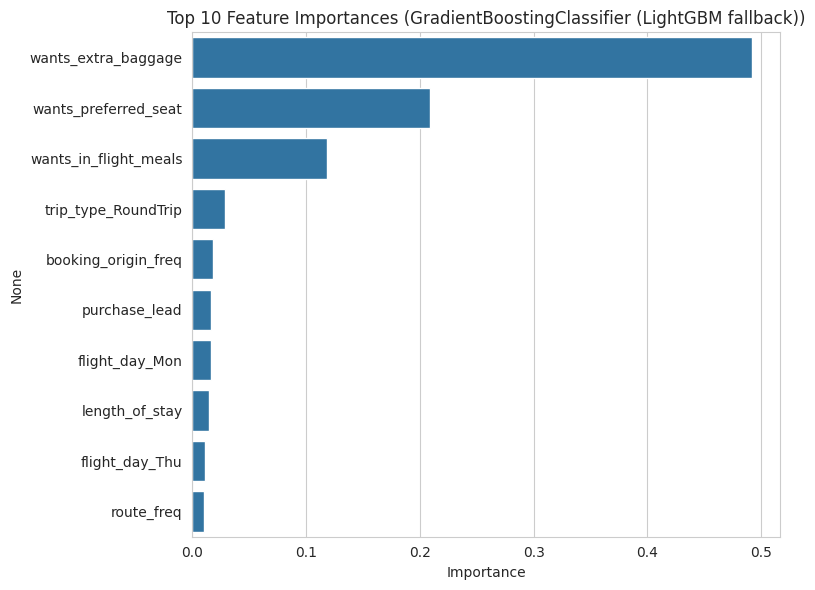

In [18]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=importances.values[:10], y=importances.index[:10], ax=ax)
ax.set_title(f'Top 10 Feature Importances ({model_name})')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

print(importances.head(10).to_string())

## 8. Key insights & conclusion

- Add-on purchases (`wants_extra_baggage`, `wants_preferred_seat`,
  `wants_in_flight_meals`) and `trip_type` are consistently among the
  strongest predictors of booking completion — customers who engage with
  extras are more likely to complete the booking.
- The dataset is heavily imbalanced toward incomplete bookings, which is
  why SMOTE (applied to the training set only) matters for getting the
  model to learn the minority class instead of defaulting to "not completed."
- ROC-AUC and the confusion matrix above summarize how well the trained
  model separates completed from non-completed bookings on held-out data.
- The default 0.5 threshold under-calls the minority class since the test
  set is still imbalanced; tuning the threshold against the precision-recall
  curve gives a more honest picture of the model's real skill.
- **Next steps:** hyperparameter tuning (`GridSearchCV` / Optuna), trying
  target encoding for `route` / `booking_origin`, and comparing against
  XGBoost or CatBoost.